# MetaIntegrator Python: SLE Meta-Analysis

**Parallels the R MetaIntegrator Real Example vignette**

This notebook demonstrates the complete meta-analysis workflow for Systemic Lupus Erythematosus (SLE) using three public GEO datasets: GSE11909, GSE50635, GSE39088.

---

## 1. Setup and Configuration

In [1]:
# Configuration
ENABLE_ADVANCED = True
SAVE_PLOT_DATA = True  # Save raw data for each plot to CSV

import sys, os, random
from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['figure.figsize'] = (10, 6)

# Add src to path
current_dir = Path.cwd()
src_dir = current_dir.parent / 'src' if (current_dir.parent / 'src').exists() else current_dir / 'src'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

# Output directory for plot data
PLOT_DATA_DIR = Path('output_sle_tutorial_analysis/plot_data')
PLOT_DATA_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(42)
random.seed(42)
print('Environment configured.')

Environment configured.


## 2. Import Modules

In [2]:
from preprocessing.loader_factory import DataLoaderFactory, load_geo_datasets
from metaintegrator.analysis import MetaAnalyzer
from metaintegrator.core_analysis import MetaAnalysisCore

try:
    from metaintegrator.roc_analysis_engine import ROCAnalysisEngine, PooledROCAnalyzer, SummaryROCAnalyzer
    from metaintegrator.prc_analysis import PRCAnalyzer
    print('ROC/PRC modules loaded.')
except ImportError as e:
    print(f'ROC/PRC modules not available: {e}')

from metaintegrator.score_calculation import ScoreCalculator
from visualization.enhanced_plotting import EnhancedMetaAnalysisPlotter

if ENABLE_ADVANCED:
    try:
        from metaintegrator.gene_search_optimizer import GeneSearchOptimizer
        print('Advanced modules loaded.')
    except ImportError as e:
        print(f'Some advanced modules not available: {e}')

def save_plot_data(data, filename, description=''):
    """Save raw plot data to CSV for use by R or Python plotting."""
    if not SAVE_PLOT_DATA:
        return
    filepath = PLOT_DATA_DIR / filename
    if isinstance(data, pd.DataFrame):
        data.to_csv(filepath, index=True)
    elif isinstance(data, dict):
        pd.DataFrame(data).to_csv(filepath, index=False)
    print(f'  Plot data saved: {filepath}')

print('Ready.')

ROC/PRC modules loaded.
Advanced modules loaded.
Ready.


## 3. Get Public Gene Expression Data

Download three SLE datasets from GEO. First run takes ~10-15 minutes; subsequent runs use cached data.

| R                                                               | Python                                          |
|-----------------------------------------------------------------|-------------------------------------------------|
| `metaData <- getGEOData(c("GSE11909", "GSE50635", "GSE39088"))` | `datasets = loader.load_multiple(meta_studies)` |

In [3]:
meta_studies = ['GSE11909', 'GSE50635', 'GSE39088']

loader = DataLoaderFactory.create_geo_loader(
    strategy='hybrid',
    cache_dir='~/.geo_cache'
)

datasets = loader.load_multiple(meta_studies, stop_on_error=False)
print(f'\nLoaded {len(datasets)} datasets.')

INFO:preprocessing.hybrid_source:Loading GSE11909 (hybrid mode: SeriesMatrix + GEOparse)...
INFO:preprocessing.ncbi_network:FTP listing geo/series/GSE11nnn/GSE11909/matrix: 2 file(s) matching '*_series_matrix.txt.gz'
INFO:preprocessing.hybrid_source:    Found 2 matrix file(s): ['GSE11909-GPL96_series_matrix.txt.gz', 'GSE11909-GPL97_series_matrix.txt.gz']
INFO:preprocessing.ncbi_network:    Using cached: GSE11909-GPL96_series_matrix.txt.gz
INFO:preprocessing.hybrid_source:    Parsed GSE11909-GPL96_series_matrix.txt.gz: GPL96, 22283 probes × 115 samples
INFO:preprocessing.ncbi_network:    Using cached: GSE11909-GPL97_series_matrix.txt.gz
INFO:preprocessing.hybrid_source:    Parsed GSE11909-GPL97_series_matrix.txt.gz: GPL97, 22645 probes × 60 samples
INFO:preprocessing.hybrid_source:  Series Matrix: 2 platform(s): ['GPL96', 'GPL97']
INFO:preprocessing.hybrid_source:  GEOparse: 175 samples, 2 platform(s): ['GPL96', 'GPL97']
INFO:preprocessing.hybrid_source:    GPL table: 22283 rows, column


Loaded 4 datasets.


### Inspect Downloaded Data

In [4]:
total_samples = 0
all_genes = set()
for i, ds in enumerate(datasets, 1):
    n_samples = len(ds.expr.columns)
    total_samples += n_samples
    all_genes.update(ds.expr.index)
    print(f'{i}. {ds.geo_id}: Platform={ds.metadata["platform"]}, '
          f'Samples={n_samples}, Features={len(ds.expr):,}')
print(f'\nTotal samples: {total_samples}, Unique genes: {len(all_genes):,}')

1. GSE11909_GPL96: Platform=GPL96, Samples=115, Features=22,283
2. GSE11909_GPL97: Platform=GPL97, Samples=60, Features=22,645
3. GSE50635_GPL6244: Platform=GPL6244, Samples=49, Features=33,297
4. GSE39088_GPL570: Platform=GPL570, Samples=142, Features=54,675

Total samples: 366, Unique genes: 87,978


### Convert to Meta-Analysis Format

In [5]:
meta_data = {'originalData': {}, 'expr': {}, 'pheno': {}, 'class': {}}
for ds in datasets:
    geo_id = ds.geo_id
    meta_data['originalData'][geo_id] = {
        'expr': ds.expr, 'pheno': ds.pheno, 'keys': ds.keys,
        'formattedName': geo_id, 'class': None,
    }
    meta_data['expr'][geo_id] = ds.expr
    meta_data['pheno'][geo_id] = ds.pheno
    meta_data['class'][geo_id] = None
print(f'Datasets: {list(meta_data["originalData"].keys())}')

Datasets: ['GSE11909_GPL96', 'GSE11909_GPL97', 'GSE50635_GPL6244', 'GSE39088_GPL570']


## 4. Label Samples

Assign class labels: 1 = SLE (disease), 0 = healthy (control).

| R | Python |
|---|--------|
| `classFunction(dataset, column, diseaseTerms)` | Manual assignment via phenotype inspection |

In [6]:
# ---------------------------------------------------------------------------
# class assignment step-0. Imports & constants
# ---------------------------------------------------------------------------

import numpy as np
import pandas as pd
from typing import Dict, List, Tuple, Union

from metaintegrator.labeling import assign_class_labels

# disease terms that will be matched when searching for disease samples
DEFAULT_DISEASE_TERMS = ["RBP +", "RBP -", "SLE", "Patient"]
DEFAULT_POSSIBLE_COLUMNS = ['characteristics', 'title', 'Sample_title', 'subject type:ch1', 'disease state:ch1', 'characteristics_ch1']

# ---------------------------------------------------------------------------
# class assignment step-1. Helper functions
# ---------------------------------------------------------------------------

def find_classification_column(pheno: pd.DataFrame,
                               possible_columns: List[str]) -> Union[str, None]:
    """
    Return the first column name that exists in *pheno* and is in *possible_columns*.
    If none is found, return None.
    """
    for col in possible_columns:
        if col in pheno.columns:
            return col
    return None

def process_dataset(dataset_key: str,
                    disease_terms: List[str] = DEFAULT_DISEASE_TERMS,
                    possible_columns: List[str] = None) -> None:
    """
    Assign class labels to *sle_data['originalData'][dataset_key]*.
    Any exception is caught and a warning is printed – the caller
    is free to decide whether to re‑try or skip.
    """
    if possible_columns is None:
        possible_columns = DEFAULT_POSSIBLE_COLUMNS

    dataset = meta_data['originalData'][dataset_key]
    pheno = dataset['pheno']

    col = find_classification_column(pheno, possible_columns)

    if col:
        try:
            meta_data['originalData'][dataset_key] = assign_class_labels(
                dataset,
                column_name=col,
                disease_terms=disease_terms,
                dataset_name=dataset_key
            )
        except Exception as exc:
            print(f"⚠️  Could not assign labels for {dataset_key} ({col}): {exc}")
            print("   Manual inspection needed.")
    else:
        print(f"⚠️  No suitable column found for {dataset_key} – skipping label assignment.")


In [7]:
# ---------------------------------------------------------------------------
# class assignment step-2. map dataset patterns → (possible_columns, disease_terms)
# ---------------------------------------------------------------------------

print("\n" + "="*80)
print("🏷️  ASSIGNING CLASS LABELS TO EACH DATASET")
print("="*80)

# disease terms that will be matched when searching for disease samples
MY_DEFAULT_DISEASE_TERMS = ["RBP +", "RBP -", "SLE"]

labeling_config = {
    'GSE50635': {
        'possible_columns': [
            'characteristics', 'title', 'Sample_title',
            'subject type:ch1', 'disease state:ch1', 'characteristics_ch1'
        ],
        'disease_terms': MY_DEFAULT_DISEASE_TERMS
    },
    'GSE11909': {
        'possible_columns': [
            'characteristics', 'characteristics_ch1',
            'Sample_characteristics_ch1', 'Illness:ch1',
            'disease state:ch1', 'characteristics_ch1'
        ],
        'disease_terms': MY_DEFAULT_DISEASE_TERMS
    },
    'GSE39088': {
        'possible_columns': [
            'characteristics', 'title', 'Sample_title',
            'disease state:ch1', 'characteristics_ch1'
        ],
        'disease_terms': ['SLE', 'Patient']
    }
}

# Iterate over the keys of sle_data['originalData'] once, applying
# the appropriate spec if it matches the dataset name
for dataset_key in meta_data['originalData'].keys():
    for pattern, spec in labeling_config.items():
        if pattern in dataset_key:
            process_dataset(
                dataset_key,
                disease_terms=spec['disease_terms'],
                possible_columns=spec['possible_columns']
            )
            break   # stop after first match

print('\nLabeling complete.')

INFO:metaintegrator.labeling:GSE11909_GPL96: assigned class labels — 103 cases, 12 controls (column='characteristics', disease_terms=['RBP +', 'RBP -', 'SLE'])
INFO:metaintegrator.labeling:GSE11909_GPL97: assigned class labels — 53 cases, 7 controls (column='characteristics', disease_terms=['RBP +', 'RBP -', 'SLE'])
INFO:metaintegrator.labeling:GSE50635_GPL6244: assigned class labels — 33 cases, 16 controls (column='characteristics', disease_terms=['RBP +', 'RBP -', 'SLE'])
INFO:metaintegrator.labeling:GSE39088_GPL570: assigned class labels — 78 cases, 64 controls (column='characteristics', disease_terms=['SLE', 'Patient'])



🏷️  ASSIGNING CLASS LABELS TO EACH DATASET

Labeling complete.


In [8]:
def validate_class(dataset_name: str,
                   dataset: Dict) -> Tuple[bool, int, int, int]:
    """
    Validate the class vector for *dataset*.
    Returns:
        (is_valid, n_disease, n_control, n_unknown)
    """
    # ── 1. Basic sanity checks ----------------------------------------------
    if 'class' not in dataset:
        print(f"   ❌ No 'class' key found")
        return False, 0, 0, 0

    class_data = dataset['class']

    if class_data is None:
        print(f"   ❌ Class is None")
        return False, 0, 0, 0

    if isinstance(class_data, (int, float, bool, np.integer, np.floating, np.bool_)):
        print(f"   ❌ ERROR: Class is a SCALAR {type(class_data).__name__}: {class_data}")
        print(f"      Expected: array with {dataset['expr'].shape[1]} values")
        print("      This dataset cannot be used for meta-analysis")
        return False, 0, 0, 0

    # ── 2. Convert to numpy array --------------------------------------------
    try:
        if isinstance(class_data, pd.Series):
            class_array = class_data.values
        elif isinstance(class_data, list):
            class_array = np.array(class_data)
        elif isinstance(class_data, np.ndarray):
            class_array = class_data
        else:
            print(f"   ❌ Unknown class type: {type(class_data)}")
            return False, 0, 0, 0
    except Exception as exc:
        print(f"   ❌ Cannot convert to array: {exc}")
        return False, 0, 0, 0

    # ── 3. Basic dimensional checks -------------------------------------------
    if len(class_array) == 0:
        print("   ❌ Empty class array")
        return False, 0, 0, 0

    expected_samples = dataset['expr'].shape[1]
    if len(class_array) != expected_samples:
        print(f"   ❌ Length mismatch: {len(class_array)} labels vs {expected_samples} samples")
        return False, 0, 0, 0

    # ── 4. Count classes ------------------------------------------------------
    try:
        n_disease  = int((class_array == 1).sum())
        n_control  = int((class_array == 0).sum())
        n_unknown  = len(class_array) - n_disease - n_control

        print(f"   🔴 Disease (SLE): {n_disease}")
        print(f"   🟢 Control: {n_control}")
        if n_unknown > 0:
            print(f"   ⚪ Unknown/Other: {n_unknown}")
        print(f"   📊 Total: {len(class_array)}")

        # ── 5. Meta‑analysis readiness -----------------------------------------
        if n_disease < 2:
            print(f"   ⚠️  Insufficient disease samples (need ≥2, have {n_disease})")
            return False, n_disease, n_control, n_unknown
        if n_control < 2:
            print(f"   ⚠️  Insufficient control samples (need ≥2, have {n_control})")
            return False, n_disease, n_control, n_unknown

        print("   ✅ VALID for meta‑analysis")
        return True, n_disease, n_control, n_unknown

    except Exception as exc:
        print(f"   ❌ ERROR counting classes: {exc}")
        return False, 0, 0, 0


In [9]:
# -------------------------------------------------------------
# Validation sample labeling & summary
# -------------------------------------------------------------
total_disease = 0
total_control = 0
valid_datasets: List[str] = []
problematic_datasets: List[Tuple[str, str]] = []

print("="*80)
print("CLASS LABEL VALIDATION & SUMMARY")
print("="*80)

for dataset_name, dataset in meta_data['originalData'].items():
    print(f"\n{dataset_name}:")

    valid, n_disease, n_control, _ = validate_class(dataset_name, dataset)

    if valid:
        total_disease += n_disease
        total_control += n_control
        valid_datasets.append(dataset_name)
    else:
        # Gather reason for failure from validate_class's prints
        # (the function already prints a short description)
        problematic_datasets.append((dataset_name, "See above message"))


CLASS LABEL VALIDATION & SUMMARY

GSE11909_GPL96:
   🔴 Disease (SLE): 103
   🟢 Control: 12
   📊 Total: 115
   ✅ VALID for meta‑analysis

GSE11909_GPL97:
   🔴 Disease (SLE): 53
   🟢 Control: 7
   📊 Total: 60
   ✅ VALID for meta‑analysis

GSE50635_GPL6244:
   🔴 Disease (SLE): 33
   🟢 Control: 16
   📊 Total: 49
   ✅ VALID for meta‑analysis

GSE39088_GPL570:
   🔴 Disease (SLE): 78
   🟢 Control: 64
   📊 Total: 142
   ✅ VALID for meta‑analysis


In [10]:
# -------------------------------------------------------------
# Final summary
# -------------------------------------------------------------
print("\n" + "="*80)
print("SUMMARY")
print("="*80)

print(f"\n✅ VALID DATASETS ({len(valid_datasets)}):")
for name in valid_datasets:
    print(f"   - {name}")

if problematic_datasets:
    print(f"\n❌ PROBLEMATIC DATASETS ({len(problematic_datasets)}):")
    for name, reason in problematic_datasets:
        print(f"   - {name}: {reason}")

print(f"\n📊 TOTALS (valid datasets only):")
print(f"   🔴 Total Disease: {total_disease}")
print(f"   🟢 Total Control: {total_control}")
print(f"   📈 Grand Total: {total_disease + total_control}")

if len(valid_datasets) == 0:
    print(f"\n⚠️  WARNING: NO VALID DATASETS!")
    print("   Cannot perform meta‑analysis without valid data")
    print("   See problematic datasets list above")
elif len(valid_datasets) < 3:
    print(f"\n⚠️  WARNING: Only {len(valid_datasets)} valid datasets")
    print("   Meta‑analysis typically requires 3+ datasets for reliable results")

print("="*80)


SUMMARY

✅ VALID DATASETS (4):
   - GSE11909_GPL96
   - GSE11909_GPL97
   - GSE50635_GPL6244
   - GSE39088_GPL570

📊 TOTALS (valid datasets only):
   🔴 Total Disease: 267
   🟢 Total Control: 99
   📈 Grand Total: 366


## 5. Run Meta-Analysis

| R                           | Python                                        |
|-----------------------------|-----------------------------------------------|
| `runMetaAnalysis(metaData)` | `MetaAnalyzer().run_meta_analysis(meta_data)` |

In [11]:
analyzer = MetaAnalyzer()
meta_analysis_obj = analyzer.run_meta_analysis(meta_object=meta_data)
print('Meta-analysis complete.')

# Inspect results
if 'metaAnalysis' in meta_analysis_obj:
    pooled = meta_analysis_obj['metaAnalysis'].get('pooledResults')
    if pooled is not None:
        n_total = len(pooled)
        n_sig = sum(pooled.get('effectSizeFDR', pd.Series()) < 0.05) if 'effectSizeFDR' in pooled.columns else 0
        print(f'Genes analyzed: {n_total}')
        print(f'Significant (FDR < 0.05): {n_sig}')

INFO:metaintegrator.analysis:Running main meta-analysis...
INFO:metaintegrator.analysis:Creating combined annotation table...
INFO:metaintegrator.analysis:Computing effect sizes...


Found common probes in dataset 1
Found common probes in dataset 3


INFO:metaintegrator.analysis:Computing Fisher's output...
INFO:metaintegrator.core_analysis:multimerge: Columns = ['study_0_P.up', 'study_0_P.down', 'study_1_P.up', 'study_1_P.down', 'study_2_P.up', 'study_2_P.down', 'study_3_P.up', 'study_3_P.down']
INFO:metaintegrator.analysis:Total genes analyzed: 25677
INFO:metaintegrator.analysis:Running leave-one-out analysis...
INFO:metaintegrator.analysis:Running leave-one-out analysis with 4 cores...
ERROR:metaintegrator.analysis:Subset 1 generated exception: Can't pickle local object 'MetaAnalyzer.run_leave_one_out_analysis.<locals>.analyze_subset'
ERROR:metaintegrator.analysis:Subset 2 generated exception: Can't pickle local object 'MetaAnalyzer.run_leave_one_out_analysis.<locals>.analyze_subset'
ERROR:metaintegrator.analysis:Subset 3 generated exception: Can't pickle local object 'MetaAnalyzer.run_leave_one_out_analysis.<locals>.analyze_subset'
ERROR:metaintegrator.analysis:Subset 4 generated exception: Can't pickle local object 'MetaAnalyz

Meta-analysis complete.
Genes analyzed: 25677
Significant (FDR < 0.05): 2552


In [12]:
print(f"\n📊 Final gene ranking (top 10 by FDR):")

final_results = meta_analysis_obj.get('metaAnalysis').get("pooledResults")
top_10 = final_results.nsmallest(10, "effectSizeFDR")[
    ["effectSize", "effectSizeFDR"]
]
print(top_10.to_string())


📊 Final gene ranking (top 10 by FDR):
         effectSize  effectSizeFDR
CD6       -0.804068   1.210617e-34
FCAR       0.866711   1.091883e-33
EIF4B     -0.982140   3.784352e-30
NAP1L1    -0.747514   9.154083e-30
HNRNPA0   -1.008347   1.230646e-26
IGLC1      0.448831   1.807723e-26
KMT2A     -0.531750   1.810767e-26
DDX6      -1.053701   1.810767e-26
KAT6B     -0.778608   4.984368e-26
FCGR1B     1.176721   2.602901e-25


## 6. Filter Genes

Identify gene signature using effect size threshold = 1 and FDR < 0.05.

| R                                                                  | Python                                                                            |
|--------------------------------------------------------------------|-----------------------------------------------------------------------------------|
| `filterGenes(metaAnalysisObj, effectSizeThresh=1, FDRThresh=0.05)` | `analyzer.filter_genes(meta_analysis_obj, effect_size_thresh=1, fdr_thresh=0.05)` |

In [13]:
meta_analysis_obj = analyzer.filter_genes(
    meta_object=meta_analysis_obj,
    effect_size_thresh=1,
    fdr_thresh=0.05
)

# Inspect filtered results
if 'filterResults' in meta_analysis_obj and meta_analysis_obj['filterResults']:
    fr_dict = meta_analysis_obj['filterResults'].to_dict()
    pos_genes = fr_dict.get('posGeneNames', [])
    neg_genes = fr_dict.get('negGeneNames', [])

    print(f'Up-regulated genes: {len(pos_genes)}')
    print(f'Down-regulated genes: {len(neg_genes)}')
    print(f'Total signature: {len(pos_genes) + len(neg_genes)}')
    if pos_genes:
        print(f'Top 5 up: {pos_genes[:5]}')
    if neg_genes:
        print(f'Top 5 down: {neg_genes[:5]}')

INFO:metaintegrator.analysis:filter_genes: starting with 25677 genes, thresholds: |ES|≥1.00, FDR≤0.0500, nStudies≥1, hetPval≥0.00, LOO=True
INFO:metaintegrator.analysis:filter_genes complete: 67 positive, 28 negative genes


Up-regulated genes: 67
Down-regulated genes: 28
Total signature: 95
Top 5 up: ['FCGR1B', 'MT1F', 'IFI27', 'FCGR1C', 'NTNG2']
Top 5 down: ['HNRNPA0', 'DDX6', 'GPRASP1', 'ABCB1', 'MID2']


## 7. Calculate Meta Score

| R | Python |
|---|--------|
| `calculateScore(filterObject, datasetObject)` | `analyzer.calculate_score(filter_result, dataset)` |

In [14]:
if 'filterResults' in meta_analysis_obj and meta_analysis_obj['filterResults']:
    filter_result = meta_analysis_obj['filterResults'].to_dict()
    for geo_id, ds in meta_analysis_obj['originalData'].items():
        scores = ScoreCalculator.calculate_score(filter_result, ds)

        ds['metaScore'] = scores
        print(f'{geo_id}: MetaScore range [{scores.min():.3f}, {scores.max():.3f}]')
    print('\nScore calculation complete.')

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 115)
INFO:metaintegrator.score_calculation:Used 67 of 67 pos genes, and 28 of 28 neg genes
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22645 probes


GSE11909_GPL96: MetaScore range [-2.317, 1.899]


INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 60)
INFO:metaintegrator.score_calculation:Used 67 of 67 pos genes, and 28 of 28 neg genes
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 49)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 49)
INFO:metaintegrator.score_calculation:Used 67 of 67 pos genes, and 28 of 28 neg genes
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 54675 probes


GSE11909_GPL97: MetaScore range [-2.241, 2.066]
GSE50635_GPL6244: MetaScore range [-2.120, 1.978]


INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 142)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 54675 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 142)
INFO:metaintegrator.score_calculation:Used 67 of 67 pos genes, and 28 of 28 neg genes


GSE39088_GPL570: MetaScore range [-1.743, 2.350]

Score calculation complete.


## 8. Visualizations

Each visualization saves its raw data to `output_sle_tutorial_analysis/plot_data/` for use by R or standalone Python plotting scripts.

### 8.1 Heatmap of Gene Effect Sizes

  Plot data saved: output_sle_tutorial_analysis/plot_data/heatmap_effect_sizes.csv


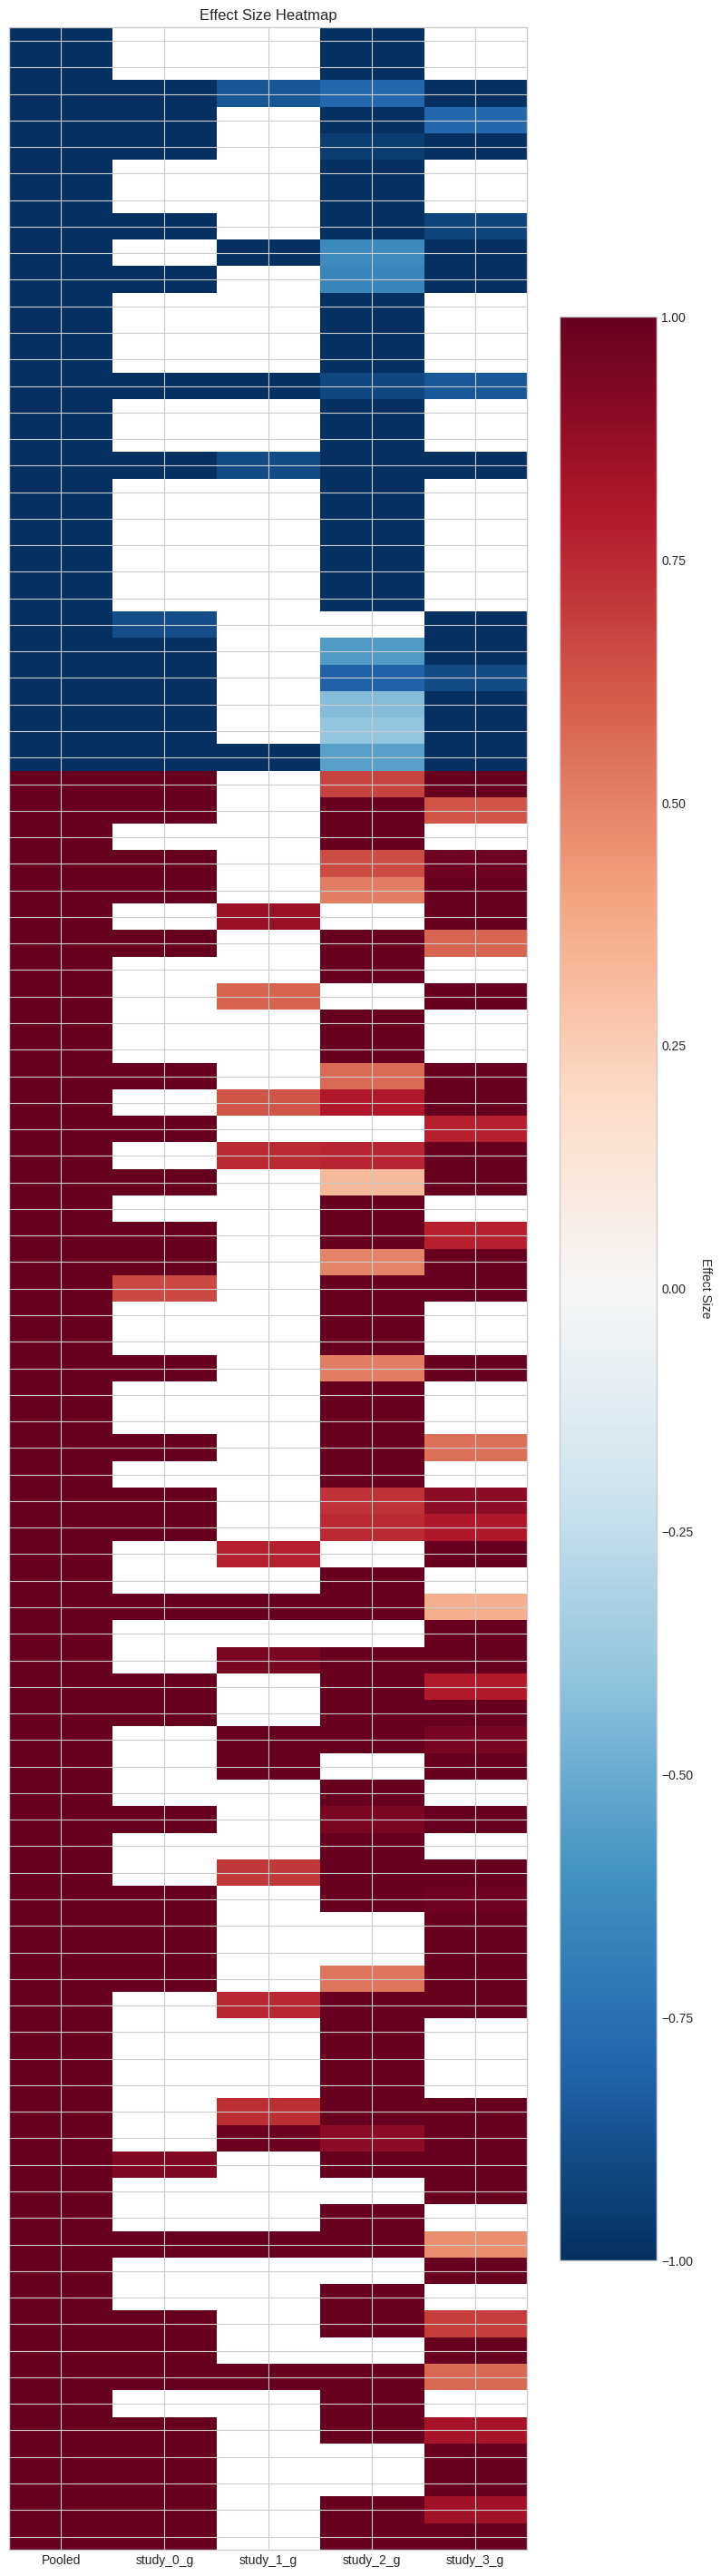

In [15]:
plotter = EnhancedMetaAnalysisPlotter()

if 'filterResults' in meta_analysis_obj and meta_analysis_obj['filterResults']:
    filter_results = meta_analysis_obj['filterResults'].to_dict()
    fig = plotter.heatmap_plot(
        meta_data=meta_analysis_obj,
        filter_object=filter_results,
        save_path='output_sle_tutorial_analysis/heatmap_effect_sizes.png'
    )
    # Save raw data
    if 'metaAnalysis' in meta_analysis_obj:
        es_df = meta_analysis_obj['metaAnalysis'].get('datasetEffectSizes')
        if es_df is not None:
            sig_genes = (filter_results.get('posGeneNames', []) +
                        filter_results.get('negGeneNames', []))
            filtered_es = es_df.loc[es_df.index.isin(sig_genes)]

            save_plot_data(filtered_es, 'heatmap_effect_sizes.csv',
                           'Gene effect sizes for signature genes')
            
    plt.show()

### 8.2-8.5 ROC Curves (Single, Multiple, Summary, Pooled)

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 115)


  Plot data saved: output_sle_tutorial_analysis/plot_data/roc_single_GSE11909_GPL96.csv


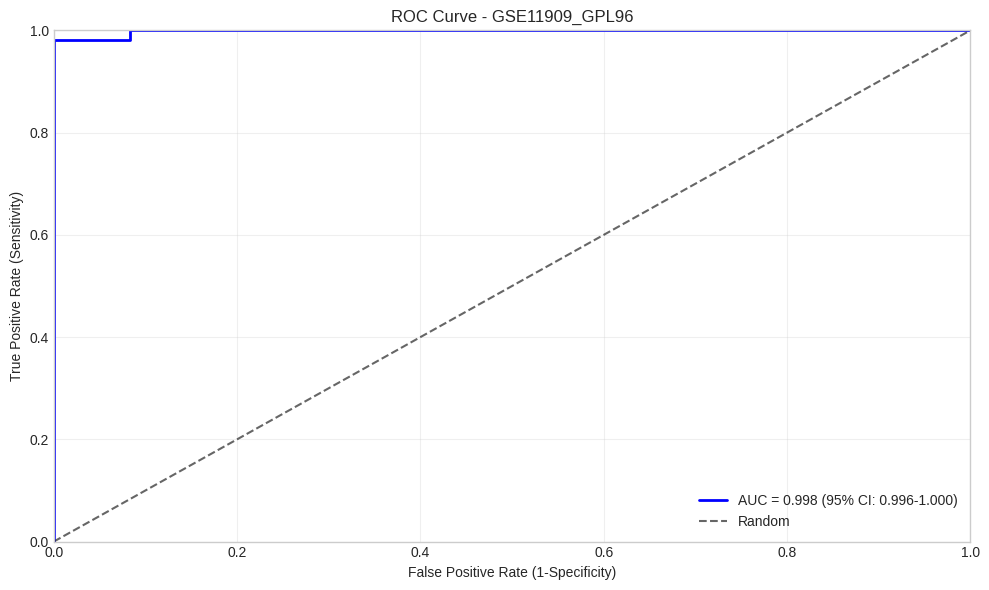

In [16]:
# Single ROC

if 'filterResults' in meta_analysis_obj and meta_analysis_obj['filterResults']:
    first_dataset_name = list(meta_analysis_obj['originalData'].keys())[0]
    first_dataset = meta_analysis_obj['originalData'][first_dataset_name]
    
    try:
        filter_results = meta_analysis_obj['filterResults'].to_dict()

        # Calculate scores for the dataset
        scores = ScoreCalculator.calculate_score(
            filter_results, first_dataset, suppress_messages=True
        )
        y_true = np.array(first_dataset['class'])
        
        fig = plotter.roc_plot(
            y_true=y_true,
            y_scores=scores,
            title=f'ROC Curve - {first_dataset_name}',
            save_path=f'output_sle_tutorial_analysis/roc_single_{first_dataset_name}.png'
        )        

        # Save raw ROC data
        if SAVE_PLOT_DATA:
            from sklearn.metrics import roc_curve, auc
            fpr, tpr, _ = roc_curve(y_true, scores)
            roc_data = pd.DataFrame({'FPR': fpr, 'TPR': tpr})
            save_plot_data(roc_data, f'roc_single_{first_dataset_name}.csv',
                           f'ROC data for {first_dataset_name}')

        plt.show()
    except Exception as e:
        print(f'ROC plot error: {e}')

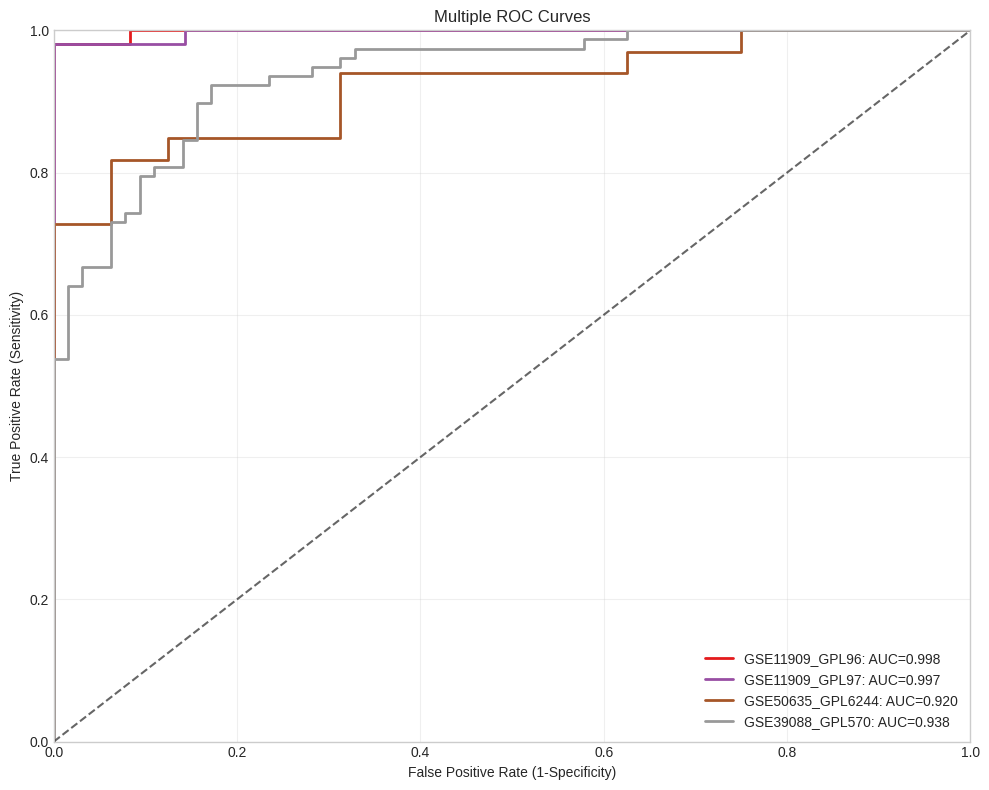

In [17]:
# Multiple ROC
try:
    filter_results = meta_analysis_obj['filterResults'].to_dict()
    datasets = list(meta_analysis_obj['originalData'].values())
    
    fig = plotter.multiple_roc_plot(
        datasets=datasets,
        filter_object=filter_results,
        title='Multiple ROC Curves',
        save_path='output_sle_tutorial_analysis/roc_multiple.png'
    )
    plt.show()
except Exception as e:
    print(f'Multiple ROC error: {e}')

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 49)
INFO:metaintegrator.sample_l

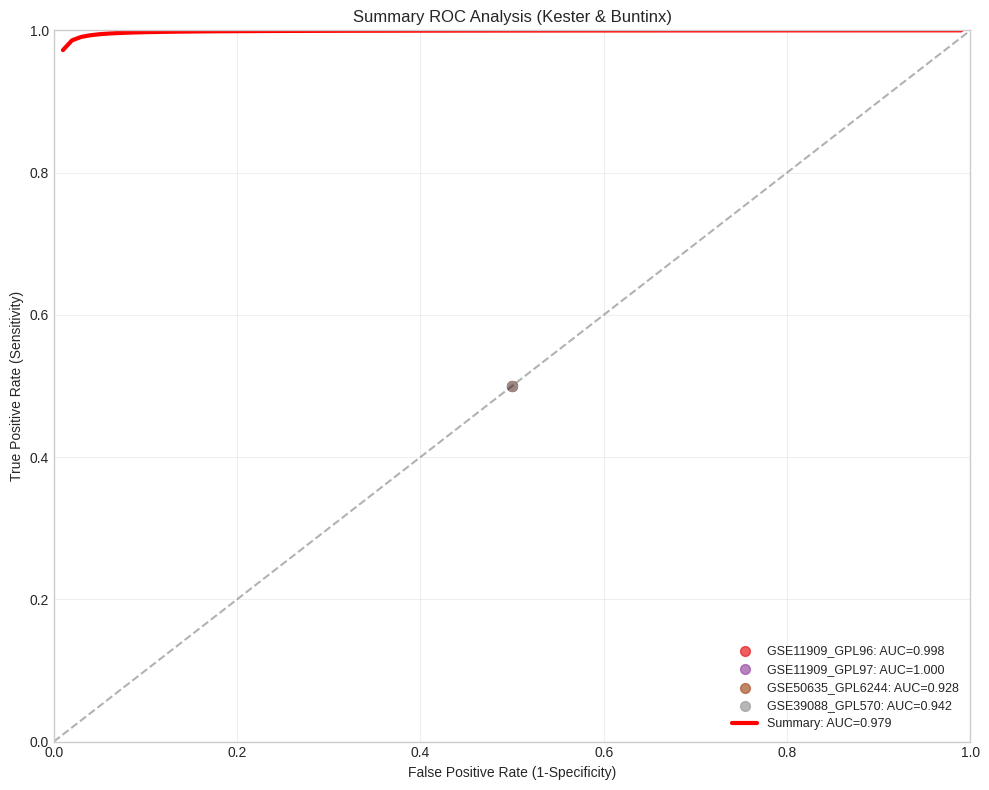

In [18]:
# Summary ROC
from metaintegrator.roc_analysis_engine import SummaryROCAnalyzer

try:
    filter_results = meta_analysis_obj['filterResults'].to_dict()
    
    summary_analyzer = SummaryROCAnalyzer()
    fig = summary_analyzer.summary_roc_plot(
        meta_object=meta_analysis_obj,
        filter_object=filter_results,
        boot_reps=100,
        save_path='output_sle_tutorial_analysis/roc_summary.png'
    )
    plt.show()
except Exception as e:
    print(f'Summary ROC error: {e}')

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 49)
INFO:metaintegrator.sample_l

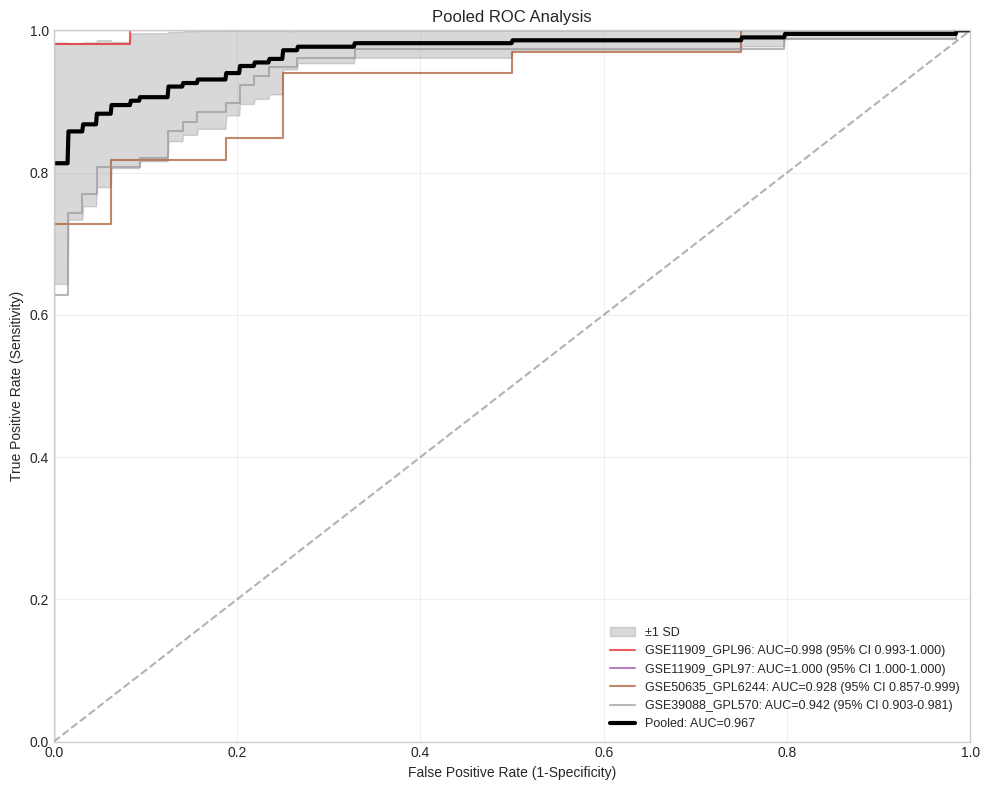

In [19]:
# Pooled ROC
from metaintegrator.roc_analysis_engine import PooledROCAnalyzer

try:
    filter_results = meta_analysis_obj['filterResults'].to_dict()
    pooled_analyzer = PooledROCAnalyzer()
    
    fig = pooled_analyzer.pooled_roc_plot(
        meta_object=meta_analysis_obj,
        filter_object=filter_results,
        smoothed=False,   # Simple weighted pooling
        save_path='output_sle_tutorial_analysis/roc_pooled.png'
    )
    plt.show()
except Exception as e:
    print(f'Pooled ROC error: {e}')

### 8.6-8.7 Precision-Recall Curves

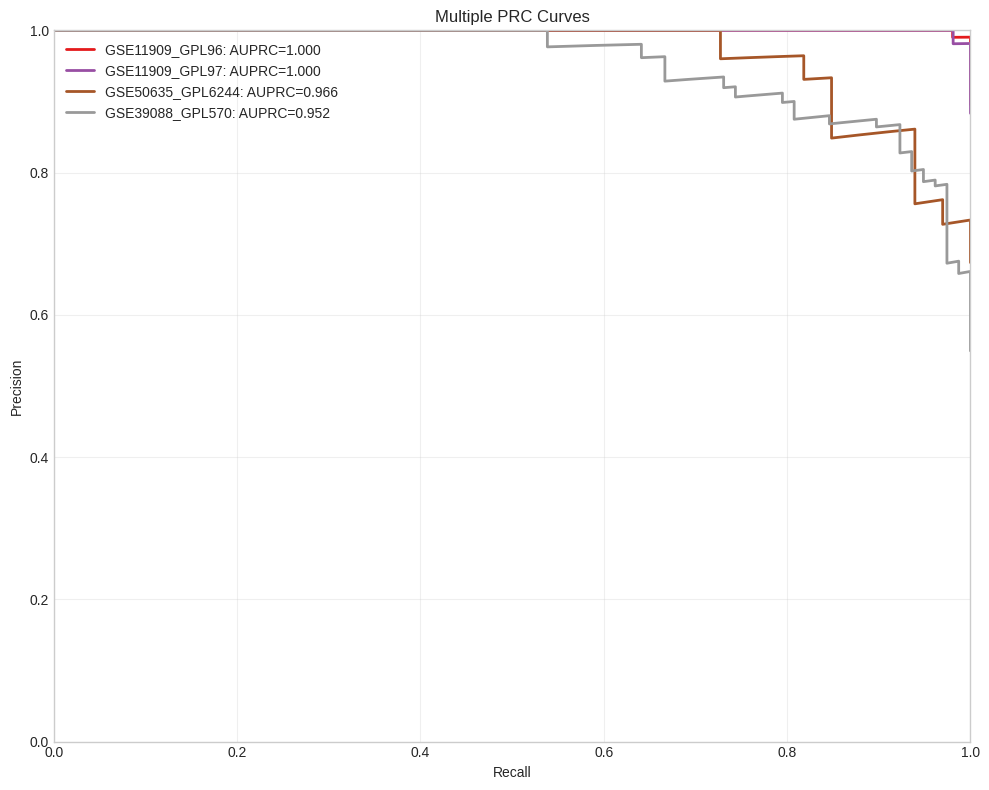

In [20]:
try:
    filter_results = meta_analysis_obj['filterResults'].to_dict()
    datasets = list(meta_analysis_obj['originalData'].values())
    
    fig = plotter.multiple_prc_plot(
        datasets=datasets,
        filter_object=filter_results,
        save_path='output_sle_tutorial_analysis/prc_multiple.png'
    )
    plt.show()
except Exception as e:
    print(f'PRC error: {e}')

### 8.8 Violin Plot

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 115)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 60)
INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 49)
INFO:metaintegrator.sample_l

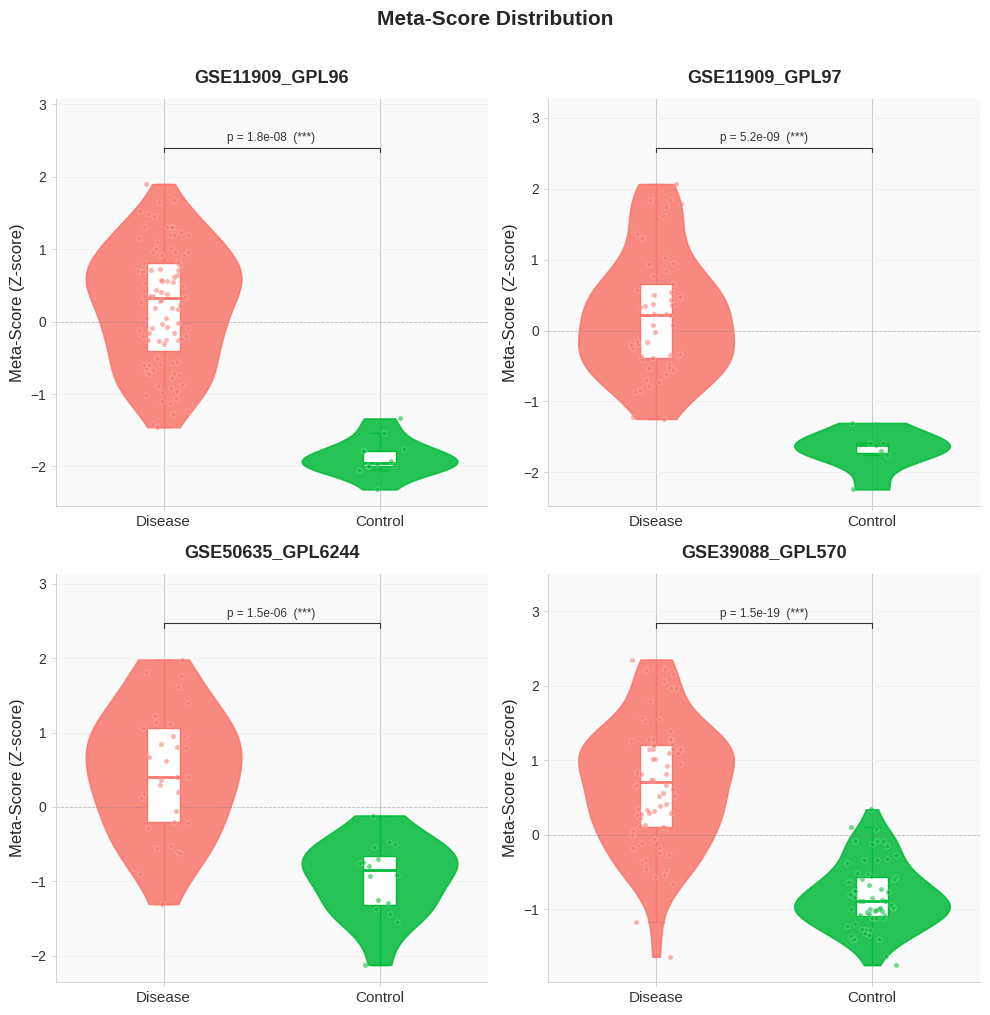

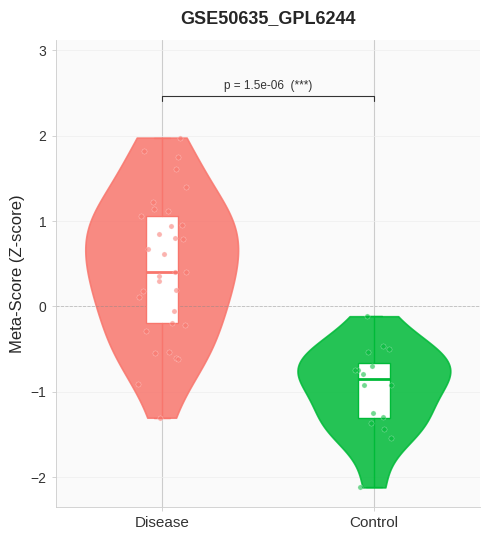

  Plot data saved: output_sle_tutorial_analysis/plot_data/violin_GSE11909_GPL96.csv
  Plot data saved: output_sle_tutorial_analysis/plot_data/violin_GSE11909_GPL97.csv
  Plot data saved: output_sle_tutorial_analysis/plot_data/violin_GSE50635_GPL6244.csv
  Plot data saved: output_sle_tutorial_analysis/plot_data/violin_GSE39088_GPL570.csv


In [21]:
from visualization.violin_plot import violin_plot, multi_violin_plot
from visualization.extract_violin_data import extract_violin_data

filter_results = meta_analysis_obj['filterResults'].to_dict()

# All datasets in a 2×2 grid (overview)
fig = multi_violin_plot(
    filter_results,
    meta_analysis_obj,
    label_column='label',
    title='Meta-Score Distribution',
    save_path='output_sle_tutorial_analysis/multi_violin_plot_scores.png',
)
plt.show()

# -----  GSE50635 – single violin by subjet type ---------------------------------
try:
    target_ds = None
    target_name = None
    for name, ds in meta_analysis_obj['originalData'].items():
        if 'GSE50635' in name:
            target_ds = ds
            target_name = name
            break

    filter_results = meta_analysis_obj['filterResults'].to_dict()

    if target_ds and 'metaScore' in target_ds:
        # Make sure we *use* the pre‑computed meta‑score
        target_ds = target_ds.copy()               # do not overwrite the original
        target_ds['score'] = target_ds['metaScore']  # <-- critical

        default_label_col = "label"
 
        fig = violin_plot(
            filter_object=filter_results,
            dataset_object=target_ds,
            label_column=default_label_col,
            title=target_name, 
            save_path=f'output_sle_tutorial_analysis/violin_{target_name}.png'
        )
        plt.show()

except Exception as e:
    print(f'Violin plot error: {e}')

# Save raw data
for ds_name, ds in meta_analysis_obj['originalData'].items():
    df = extract_violin_data(filter_results, ds, label_column='label')
    if df is not None:
        filename = f'violin_{ds_name}.csv'
        save_plot_data(df, filename,
                       f'Violin plot raw data for {ds_name}')
        

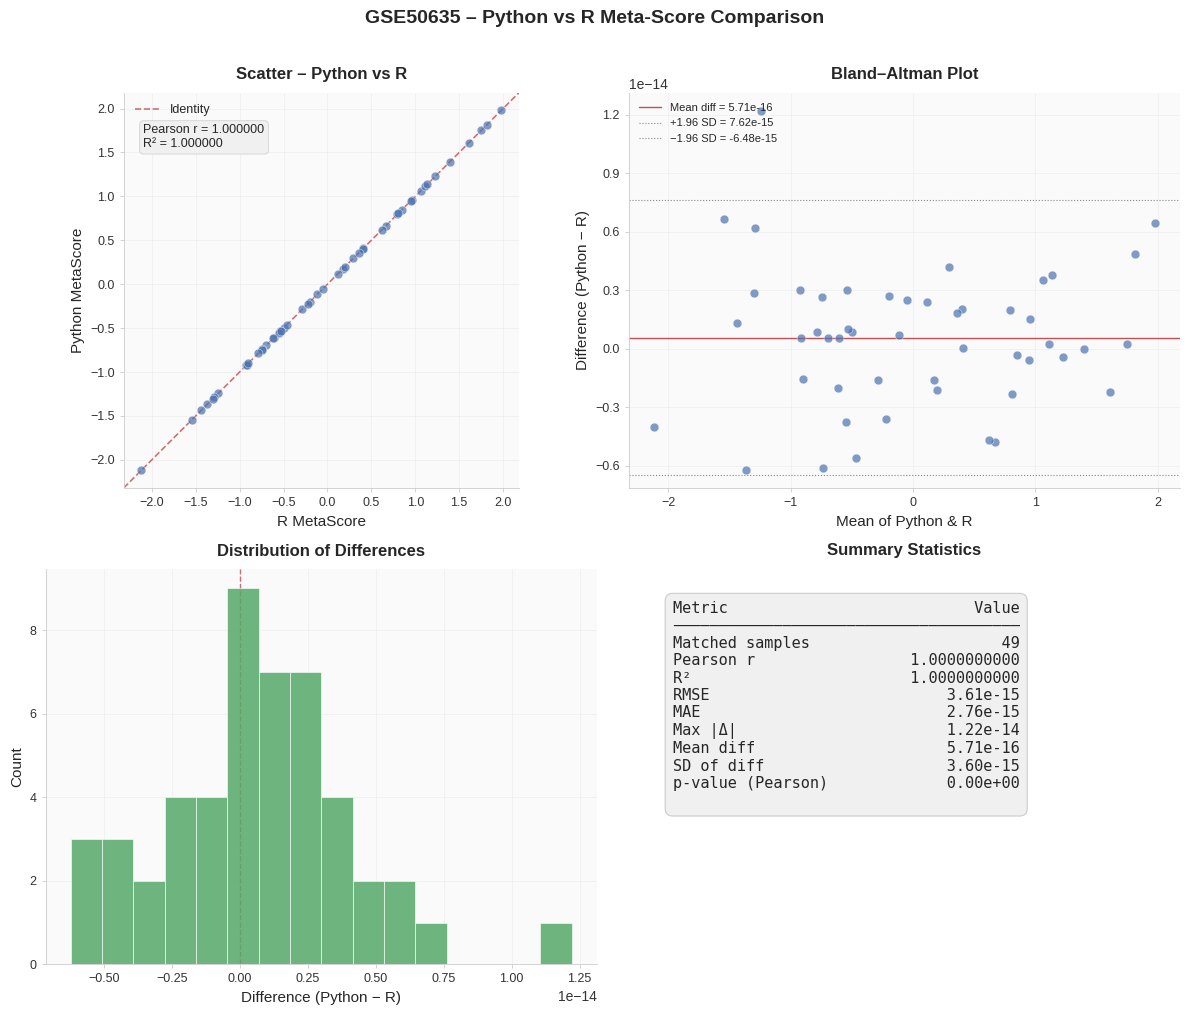

In [22]:
# ── Meta-Score Parity: Python vs R ──────────────────────────────────
#
# This cell loads the per-sample violin-plot CSVs produced by
# the Python and R pipelines, joins them on Sample ID, and
# generates a four-panel diagnostic figure:
#
#   1. Scatter (Python vs R) with identity line
#   2. Bland–Altman (mean vs difference)
#   3. Residual histogram
#   4. Summary statistics (Pearson r, R², RMSE, MAE, …)

from visualization.compare_meta_scores import compare_meta_scores

# ── paths ───────────────────────────────────────────────────────────
PYTHON_CSV = (
    "output_sle_tutorial_analysis/plot_data/"
    "violin_GSE50635_GPL6244.csv"
)
R_CSV = (
    "output_sle_tutorial_r_analysis/plot_data/"
    "violin_GSE50635_subject_type.csv"
)

fig = compare_meta_scores(
    python_csv=PYTHON_CSV,
    r_csv=R_CSV,
    title="GSE50635 – Python vs R Meta-Score Comparison",
    save_path=(
        "output_sle_tutorial_analysis/plot_data/"
        "meta_score_comparison_GSE50635.png"
    ),
)
plt.show()


### 8.9 Regression Plot

INFO:metaintegrator.sample_level_gene_data:Processing 67 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (67, 49)
INFO:metaintegrator.sample_level_gene_data:Processing 28 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (28, 49)


  Plot data saved: output_sle_tutorial_analysis/plot_data/regression_GSE50635_GPL6244_age.csv


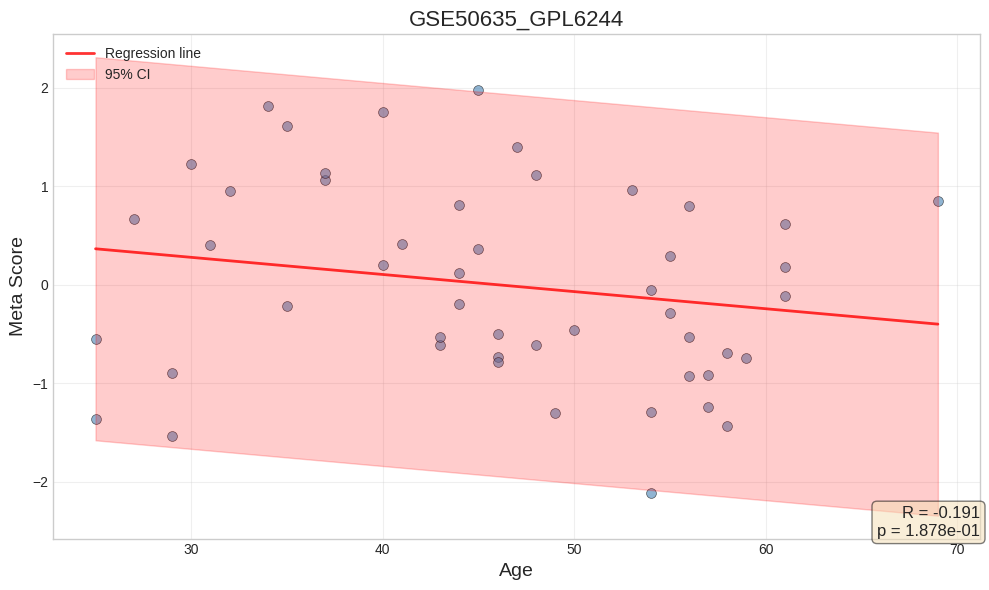

In [23]:
# Regression plot: MetaScore vs Age for GSE50635

try:
    if target_ds and 'metaScore' in target_ds:
        filter_results = meta_analysis_obj['filterResults'].to_dict()

        # Make sure we *use* the pre‑computed meta‑score
        target_ds = target_ds.copy()               # do not overwrite the original
        
        # Check which column in your dataset has value of interest for plotting
        # Get the unique values in the column as list
        # columns_of_interest = ['characteristics', 'description']
        # for col in columns_of_interest:
        #    unique_values_list = target_ds['pheno'][col].unique().tolist()
        #    print(f"\n::: for {col}: unique_values={unique_values_list}")
        #
        #    # NOTE: a value can be something like the following instead of a single number 
        #    # tissue: whole blood; gender: female; ancestry: European; subject type: Control; age: 61
            
        plotter = EnhancedMetaAnalysisPlotter()
        
        fig = plotter.regression_plot(
            filter_object=filter_results,
            dataset_object=target_ds,
            continuous_variable_column='characteristics',
            formatted_variable_name='Age',
            save_path='output_sle_tutorial_analysis/regression_GSE50635_age.png'
        )

        # Save raw data
        # 1. Pull the meta‑score (keep the pheno index)
        meta_scores = pd.Series(
            target_ds['metaScore'],
            name='MetaScore',
            index=target_ds['pheno'].index     # align indices
        )
        
        # 2. Extract age from the composite characteristics string
        age_str = target_ds['pheno']['characteristics'].astype(str)
        age_num = (
            age_str.str.extract(r'age:\s*([0-9]+(?:\.[0-9]+)?)')[0]
            .astype(float)
        )
        
        # 3. Build the data frame (index already aligned)
        reg_data = pd.concat([meta_scores, age_num.rename('Age')], axis=1)
        
        # 4. Drop rows with missing values in *any* column
        reg_data = reg_data.dropna()
        
        # 5. Save
        save_plot_data(reg_data, f'regression_{target_name}_age.csv', 'Regression plot data')
        
        plt.show()
except Exception as e:
    print(f'Regression plot error: {e}')

### 8.10 Forest Plot

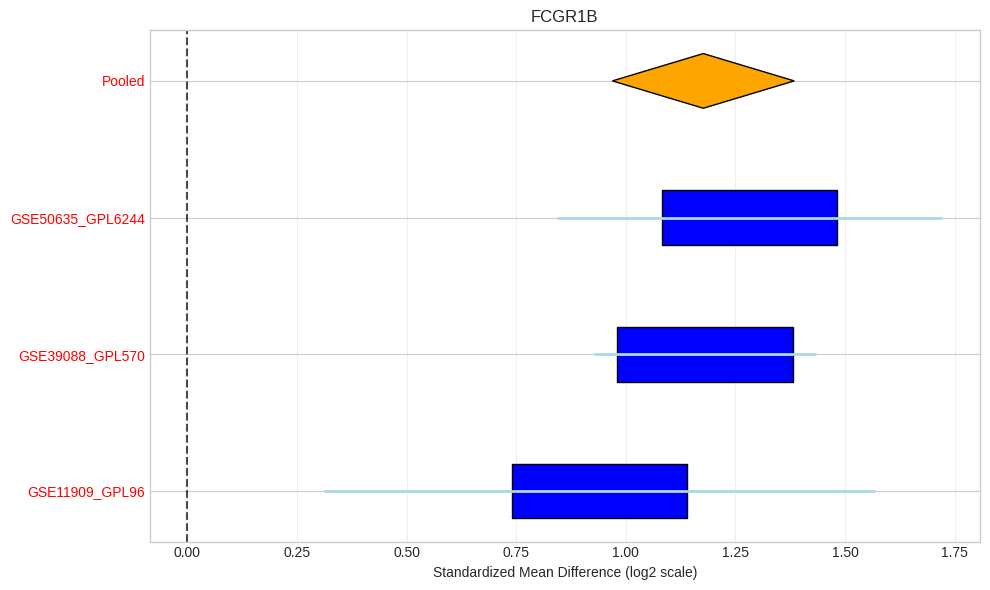

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_FCGR1B.csv


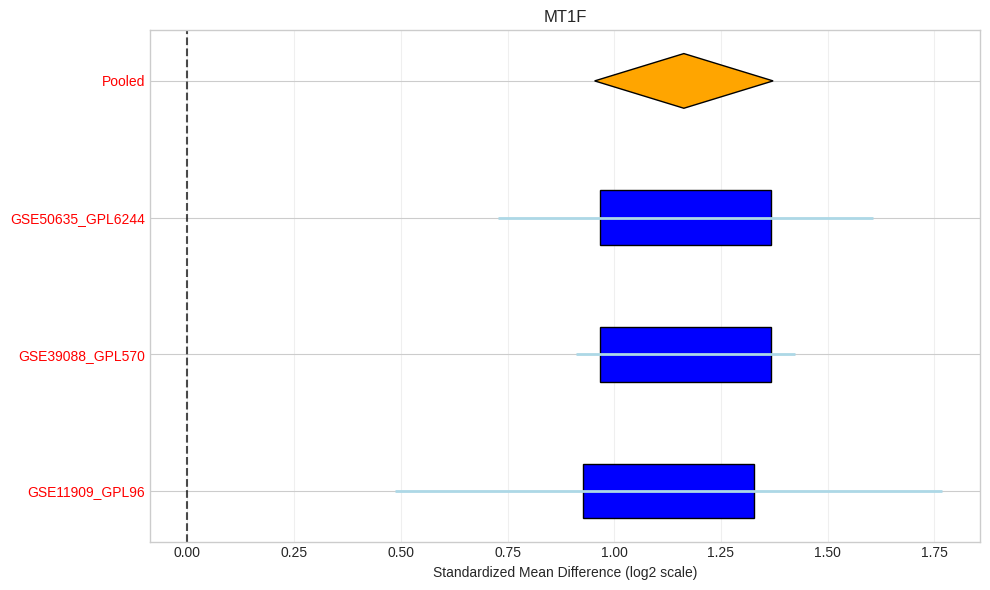

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_MT1F.csv


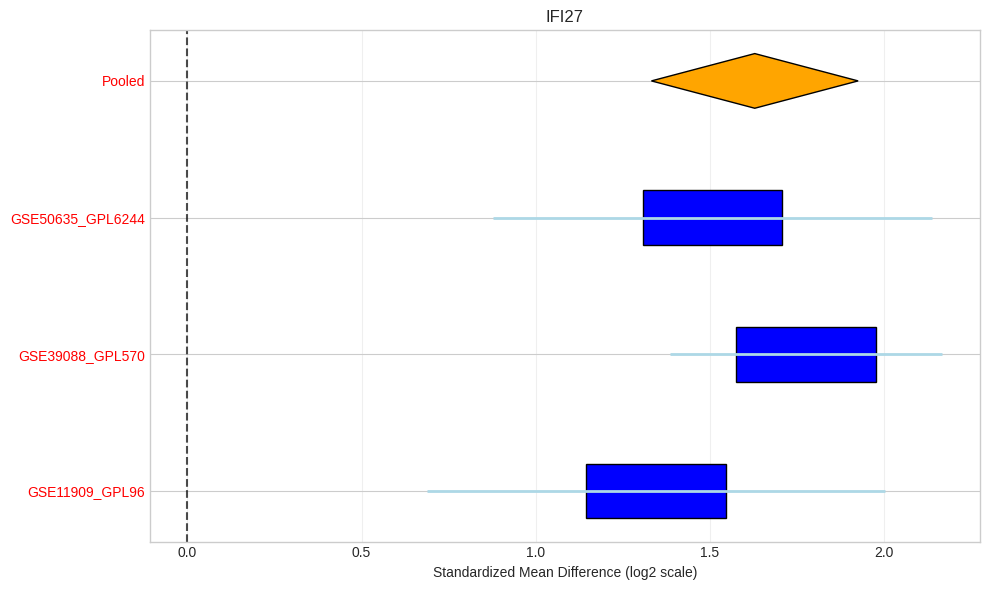

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_IFI27.csv


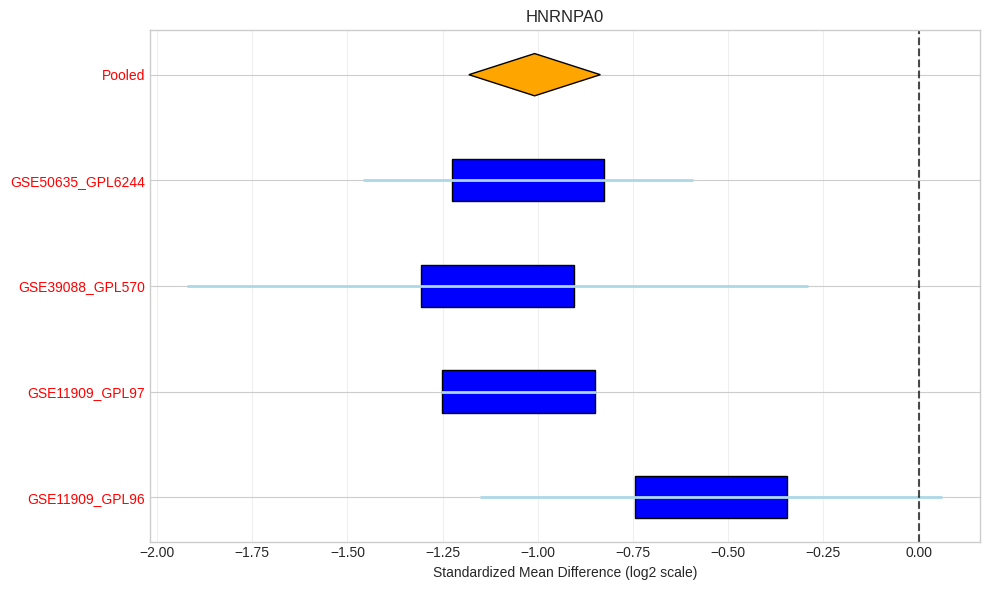

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_HNRNPA0.csv


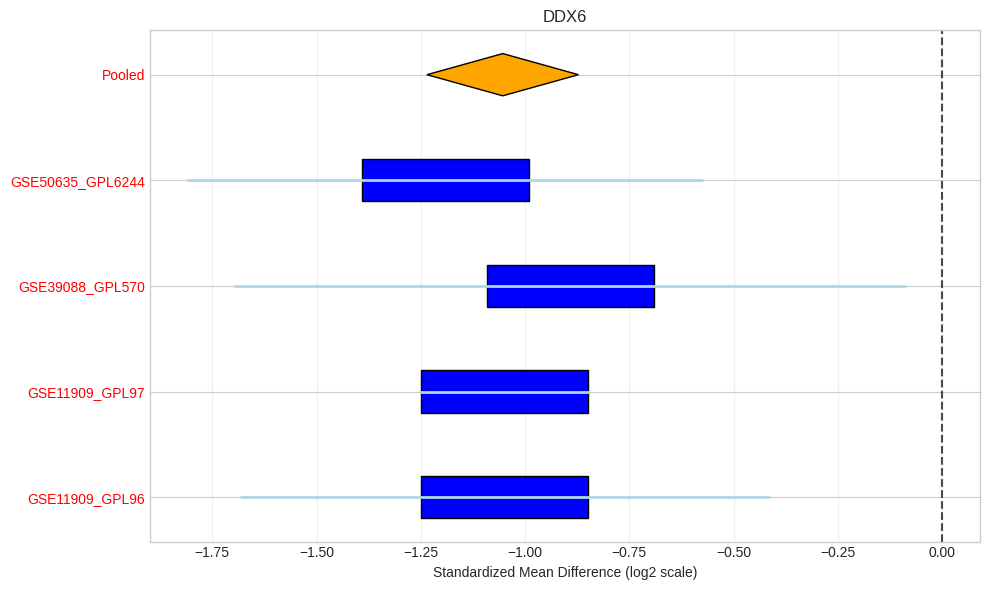

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_DDX6.csv


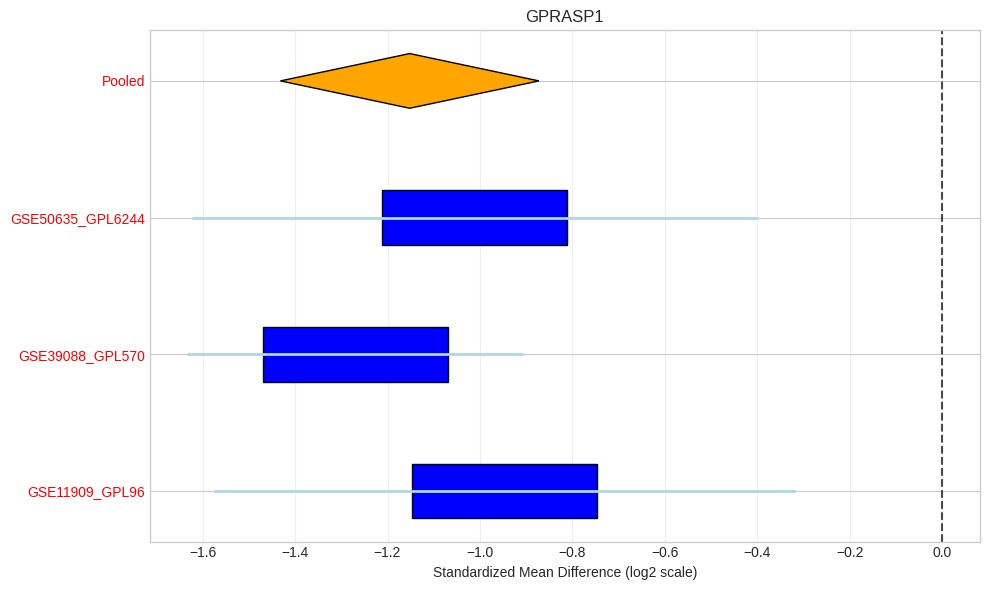

  Plot data saved: output_sle_tutorial_analysis/plot_data/forest_GPRASP1.csv


In [24]:
selected_genes = ["FCGR1B", "MT1F", "IFI27", "HNRNPA0", "DDX6", "GPRASP1"]

for gene in selected_genes:
    # Forest plot
    try:
        fig = plotter.forest_plot(
            gene_name=gene,
            meta_object=meta_analysis_obj,
            save_path=f'output_sle_tutorial_analysis/forest_{gene}.png'
        )
        plt.show()
    
        # Save raw data
        if SAVE_PLOT_DATA:
            meta_info = meta_analysis_obj.get('metaAnalysis')
            if meta_info and 'datasetEffectSizes' in meta_info:
                es_df = meta_info['datasetEffectSizes']
                if es_df is not None and gene in es_df.index:
                    forest_data = pd.DataFrame({'EffectSize': es_df.loc[gene]})
                    save_plot_data(forest_data, f'forest_{gene}.csv',
                                   f'Forest plot data for {gene}')
                    
    except Exception as e:
        print(f'Forest plot error: {e}')

## 9. Advanced Analyses (Optional)

### 9.1 Forward/Backward Search

In [25]:
# Uncomment to run
try:
    optimizer = GeneSearchOptimizer()

    filter_results = meta_analysis_obj['filterResults'].to_dict()
    backward_result = optimizer.backward_search(meta_analysis_obj, filter_results)

    print(f'Optimized signature: {len(backward_result.get("posGeneNames", [])) + len(backward_result.get("negGeneNames", []))} genes')

    print("\n✅ Backward search complete!")
    print(f"   Optimized positive genes: {len(backward_result['posGeneNames'])}")
    print(f"   Optimized negative genes: {len(backward_result['negGeneNames'])}")
    print(f"   Total genes: {len(backward_result['posGeneNames']) + len(backward_result['negGeneNames'])}")

    # Calculate performance improvement
    print("\n📊 Performance Comparison:")
    print("   Original signature genes:", len(filter_results['posGeneNames']) + len(filter_results['negGeneNames']))
    print("   Optimized signature genes:", len(backward_result['posGeneNames']) + len(backward_result['negGeneNames']))
    print("   Reduction:", len(filter_results['posGeneNames']) + len(filter_results['negGeneNames']) -
          (len(backward_result['posGeneNames']) + len(backward_result['negGeneNames'])), "genes")

except Exception as e:
    print(f"⚠️  Backward search failed: {e}")
    print("   Continuing with original filter...")
    backward_result = filter_results

# Optional: Forward search (adds genes)
print("\n💡 Forward search available for adding genes...")
print("   Use: forward_result = gene_optimizer.forward_search(meta_object, filter_results)")

print('Forward/backward search skipped (uncomment to run).')

INFO:metaintegrator.gene_search_optimizer:Starting backward search with 67 positive and 28 negative genes
INFO:metaintegrator.gene_search_optimizer:Converting probe-level data to gene-level data for all discovery datasets
INFO:metaintegrator.sample_level_gene_data:Processing 95 genes from dataset with 22283 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (95, 115)
INFO:metaintegrator.gene_search_optimizer:Processed dataset: GSE11909_GPL96
INFO:metaintegrator.sample_level_gene_data:Processing 95 genes from dataset with 22645 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (95, 60)
INFO:metaintegrator.gene_search_optimizer:Processed dataset: GSE11909_GPL97
INFO:metaintegrator.sample_level_gene_data:Processing 95 genes from dataset with 33297 probes
INFO:metaintegrator.sample_level_gene_data:Successfully processed gene data. Result shape: (95, 49)
INFO:metaintegrator.gene_search_optimizer:P

Optimized signature: 26 genes

✅ Backward search complete!
   Optimized positive genes: 15
   Optimized negative genes: 11
   Total genes: 26

📊 Performance Comparison:
   Original signature genes: 95
   Optimized signature genes: 26
   Reduction: 69 genes

💡 Forward search available for adding genes...
   Use: forward_result = gene_optimizer.forward_search(meta_object, filter_results)
Forward/backward search skipped (uncomment to run).


### 9.2 immunoStates Deconvolution

In [26]:
# Uncomment to run
# Import immunoStates deconvolution
# from metaintegrator.consolidated_immune_deconvolution import ImmunoStatesDeconvolver
#
# Initialize deconvolver
# print("\n🧬 Initializing immunoStates deconvolver...")
# immuno_deconvolver = ImmunoStatesDeconvolver()
#
# try:
#     immuno_results = immuno_deconvolver.immunostates_deconv(
#         meta_object=meta_analysis_obj,
#         max_cores=2  # Adjust based on your system
#     )
#
#     print("\n✅ Immune deconvolution complete!")
# 
#     # Handle multiple possible result structures
#     cell_props = None
#
#     # Check for cell_proportions key (some versions)
#     if 'cell_proportions' in immuno_results:
#         cell_props = immuno_results['cell_proportions']
#         print("   📊 Found results in 'cell_proportions' key")
# 
#     # Check for immunoStates key (R-like structure)
#     elif 'immunoStates' in immuno_results:
#         immuno_states = immuno_results['immunoStates']
# 
#         # Check if it's empty
#         if not immuno_states or (isinstance(immuno_states, dict) and len(immuno_states) == 0):
#             print("\\n   ⚠️  immunoStates key is empty")
#             print("   This typically means:")
#             print("      • Mock basis matrix was used (no real reference data)")
#             print("      • Gene alignment failed (no common genes)")
#             print("      • Deconvolution computation didn't complete")
#         else:
#             cell_props = immuno_states
#             print("   📊 Found results in 'immunoStates' key")
#
#     # Check if results are in the meta_object structure itself
#     elif 'originalData' in immuno_results:
#         print("   📊 Results returned in meta_object structure")
#         # Extract cell proportions from individual datasets if available
#         cell_props = {}
#         for dataset_name, dataset in immuno_results['originalData'].items():
#             if 'immunoStates' in dataset and dataset['immunoStates']:
#                 cell_props[dataset_name] = dataset['immunoStates']
#
#         if not cell_props:
#             print("   ⚠️  No cell proportions found in dataset structures")
# 
#     # Display results if we found them
#     if cell_props and len(cell_props) > 0:
#        print("\\n📊 Cell Type Proportion Summary:")
#        print(f"   Datasets analyzed: {len(cell_props)}")
# 
#        # Show example for first dataset
#        first_dataset = list(cell_props.keys())[0]
#        first_props = cell_props[first_dataset]
#
#        if isinstance(first_props, pd.DataFrame):
#             print(f"\\n   Example ({first_dataset}):")
#             print(f"   Samples: {first_props.shape[0]}")
#             print(f"   Cell types: {first_props.shape[1]}")
#             print(f"\\n   Cell type names:")
#             for ct in list(first_props.columns)[:5]:
#                 print(f"      - {ct}")
#             if len(first_props.columns) > 5:
#                 print(f"      ... and {len(first_props.columns) - 5} more")
# 
#            # Show sample data
#            print(f"\\n   Sample proportions (first 3 samples):")
#            print(first_props.head(3).to_string())
#
#         print("\\n📈 Visualization options:")
#         print("   - Box plots of cell proportions by disease status")
#         print("   - Correlation heatmaps")
#         print("   - PCA/UMAP of cell proportion profiles")
# 
#    else:
#         print("\\n⚠️  No cell proportion results found")
#         print("\\n📋 Diagnostic Information:")
#         print(f"   Result type: {type(immuno_results)}")
#         print(f"   Result keys: {list(immuno_results.keys()) if isinstance(immuno_results, dict) else 'Not a dict'}")
# 
#         if isinstance(immuno_results, dict):
#             for key in ['cell_proportions', 'immunoStates']:
#                 if key in immuno_results:
#                     value = immuno_results[key]
#                     print(f"\\n   {key}:")
#                     print(f"      Type: {type(value)}")
#                     if isinstance(value, dict):
#                         print(f"      Keys: {list(value.keys())}")
#                         print(f"      Length: {len(value)}")
#                     elif isinstance(value, pd.DataFrame):
#                         print(f"      Shape: {value.shape}")
# 
#         print("\\n💡 Possible Solutions")
#         print("   Provide actual immunoStates basis matrix:")
#         print("      deconvolver = ImmunoStatesDeconvolver(")
#         print("          basis_matrix_path='/path/to/immunoStates_matrix.csv'")
#         print("      )")
#         print("   ")
#
# except Exception as e:
#     print(f"\\n❌ immunoStates deconvolution failed: {e}")
#     print("\\n📋 Error Details:")
#     import traceback
#     traceback.print_exc()
# 
#     print("\\n💡 This is an advanced optional feature")
#     print("   Continuing without immune cell estimates...")
#     print("\\n   Common issues:")
#     print("   • Missing immunoStates reference matrix")
#     print("   • Gene name mismatch between data and reference")
#     print("   • Insufficient memory for large datasets")
# 
#     immuno_results = None
#     cell_props = None

print('immunoStates deconvolution skipped (uncomment to run).')

immunoStates deconvolution skipped (uncomment to run).


### 9.3 LINCS Drug Correlation

In [27]:
# Uncomment to run (requires large download ~1-2 GB first time)
# Import LINCS tools
# from metaintegrator.linc_tools import lincs_correlate
# filter_results = meta_analysis_obj['filterResults'].to_dict()
# reverse_hits = lincs_correlate(meta_analysis_obj, filter_results, dataset='CP', direction='reverse')

print('LINCS correlation skipped (uncomment to run).')

LINCS correlation skipped (uncomment to run).


### 9.4 COCONUT Batch Correction

In [28]:
try:
    from metaintegrator.coconut_integration import run_coconut_analysis
    coconut_result = run_coconut_analysis(meta_object=meta_analysis_obj)
    print('COCONUT correction complete.')
    if 'merged_expression' in coconut_result:
        merged = coconut_result['merged_expression']
        print(f'Merged matrix: {merged.shape[0]} genes x {merged.shape[1]} samples')
except Exception as e:
    print(f'COCONUT not available: {e}')


Treating datasets as batches: 
Standardizing Data across genes
Fitting L/S model and finding priors
Finding parametric adjustments
Adjusting the Data

Treating datasets as batches: 

Batches identical between have-params and get-params...
Adjusting the Data Based on input gamma.star and delta.star
COCONUT correction complete.


---

## 10. R-to-Python Function Mapping

| R Function | Python Equivalent                                       |
|------------|---------------------------------------------------------|
| `getGEOData()` | `DataLoaderFactory.create_geo_loader().load_multiple()` |
| `classFunction()` | `assign_class_labels()`                                 |
| `runMetaAnalysis()` | `MetaAnalyzer().run_meta_analysis()`                    |
| `filterGenes()` | `analyzer.filter_genes()`                               |
| `calculateScore()` | `analyzer.calculate_score()`                            |
| `heatmapPlot()` | `plotter.heatmap_plot()`                                |
| `rocPlot()` | `EnhancedMetaAnalysisPlotter().roc_plot()`                      |
| `multipleROCPlot()` | `EnhancedMetaAnalysisPlotter().multiple_roc_plot()`             |
| `summaryROCPlot()` | `SummaryROCAnalyzer().summary_roc_plot()`               |
| `pooledROCPlot()` | `PooledROCAnalyzer().pooled_roc_plot()`                 |
| `violinPlot()` | `violin_plot()`                                         |
| `regressionPlot()` | `EnhancedMetaAnalysisPlotter().regression_plot()`               |
| `forestPlot()` | `EnhancedMetaAnalysisPlotter().forest_plot()`                   |
| `forwardSearch()` | `GeneSearchOptimizer().forward_search()`                |
| `backwardSearch()` | `GeneSearchOptimizer().backward_search()`               |
| `coconutMetaIntegrator()` | `run_coconut_analysis()`                                |